In [1]:
.libPaths("~/R/x86_64-pc-linux-gnu-library/4.4/")

library(Seurat)
library(SeuratDisk)
library(patchwork)
library(harmony)
library(reshape2)
library(RColorBrewer)
library(dplyr)
library(readr)
library(tidyverse)
library(Matrix)
library(Seurat)
library(ggplot2)
library(cowplot)
library(celldex)
library(SingleR)
library(data.table)
library(scGate)
library(ggpubr)
library(scCustomize)

ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}


Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built under R 4.5.0 but the current version is
4.5.1; it is recomended that you reinstall ‘SeuratObject’ as the ABI
for R may have changed

‘SeuratObject’ was built with package ‘Matrix’ 1.7.3 but the current
version is 1.7.4; it is recomended that you reinstall ‘SeuratObject’ as
the ABI for ‘Matrix’ may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


Registered S3 method overwritten by 'SeuratDisk':
  method            from  
  as.sparse.H5Group Seurat

Loading required package: Rcpp


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2    

# Analysis of 5p data

## Integration of CD4 and CD8 datasets

We will load the CD4 and CD8 datasets which were prepared by the CDN team at Boston CHildren's Hospital. 

In [2]:
cd4  <- readRDS("data/cdn/gut_5p_integrated_cd4_prolif_filt.rds")
cd8  <- readRDS("data/cdn/gut_5p_integrated_CD8_with_prolif.rds")

In [3]:
library(STACAS)

In [4]:
cd8$orig_cluster  <- cd8$seurat_clusters

In [6]:
gut_t  <- merge(cd4, cd8)

Warning message:
“Some cell names are duplicated across objects provided. Renaming to enforce unique cell names.”


In [7]:
rm(cd4)
rm(cd8)

In [8]:
gut_t  <- SplitObject(gut_t, split.by = "participant_id")

# normalize and identify variable features for each dataset independently
gut_t <- lapply(X = gut_t, FUN = function(x) {
    DefaultAssay(x)  <- "RNA"
    x$barcode  <- colnames(x)
    x <- NormalizeData(x)
    x <- FindVariableFeatures(x, selection.method = "vst", nfeatures = 1200)
})


gut_allt_integrated <- Run.STACAS(gut_t, dims = 1:20)
gut_allt_integrated <- RunUMAP(gut_allt_integrated, dims = 1:20) 
DimPlot(gut_allt_integrated)
saveRDS(gut_allt_integrated, "data/gut_allt_5p_integrated.rds")


RNA3 assay doesn't leave any cells, so it is removed

Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 1.5 GiB”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 1.1 GiB”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 1.1 GiB”
Preparing PCA embeddings for objects...



In [1]:
rm(list = ls())

In [2]:
gut_allt_integrated <- readRDS("data/cdn/gut_allt_5p_integrated.rds")

In [255]:
gut_allt_integrated@assays$RNA

Assay data with 36601 features for 588063 cells
First 10 features:
 MIR1302-2HG, FAM138A, OR4F5, AL627309.1, AL627309.3, AL627309.2,
AL627309.5, AL627309.4, AP006222.2, AL732372.1 

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



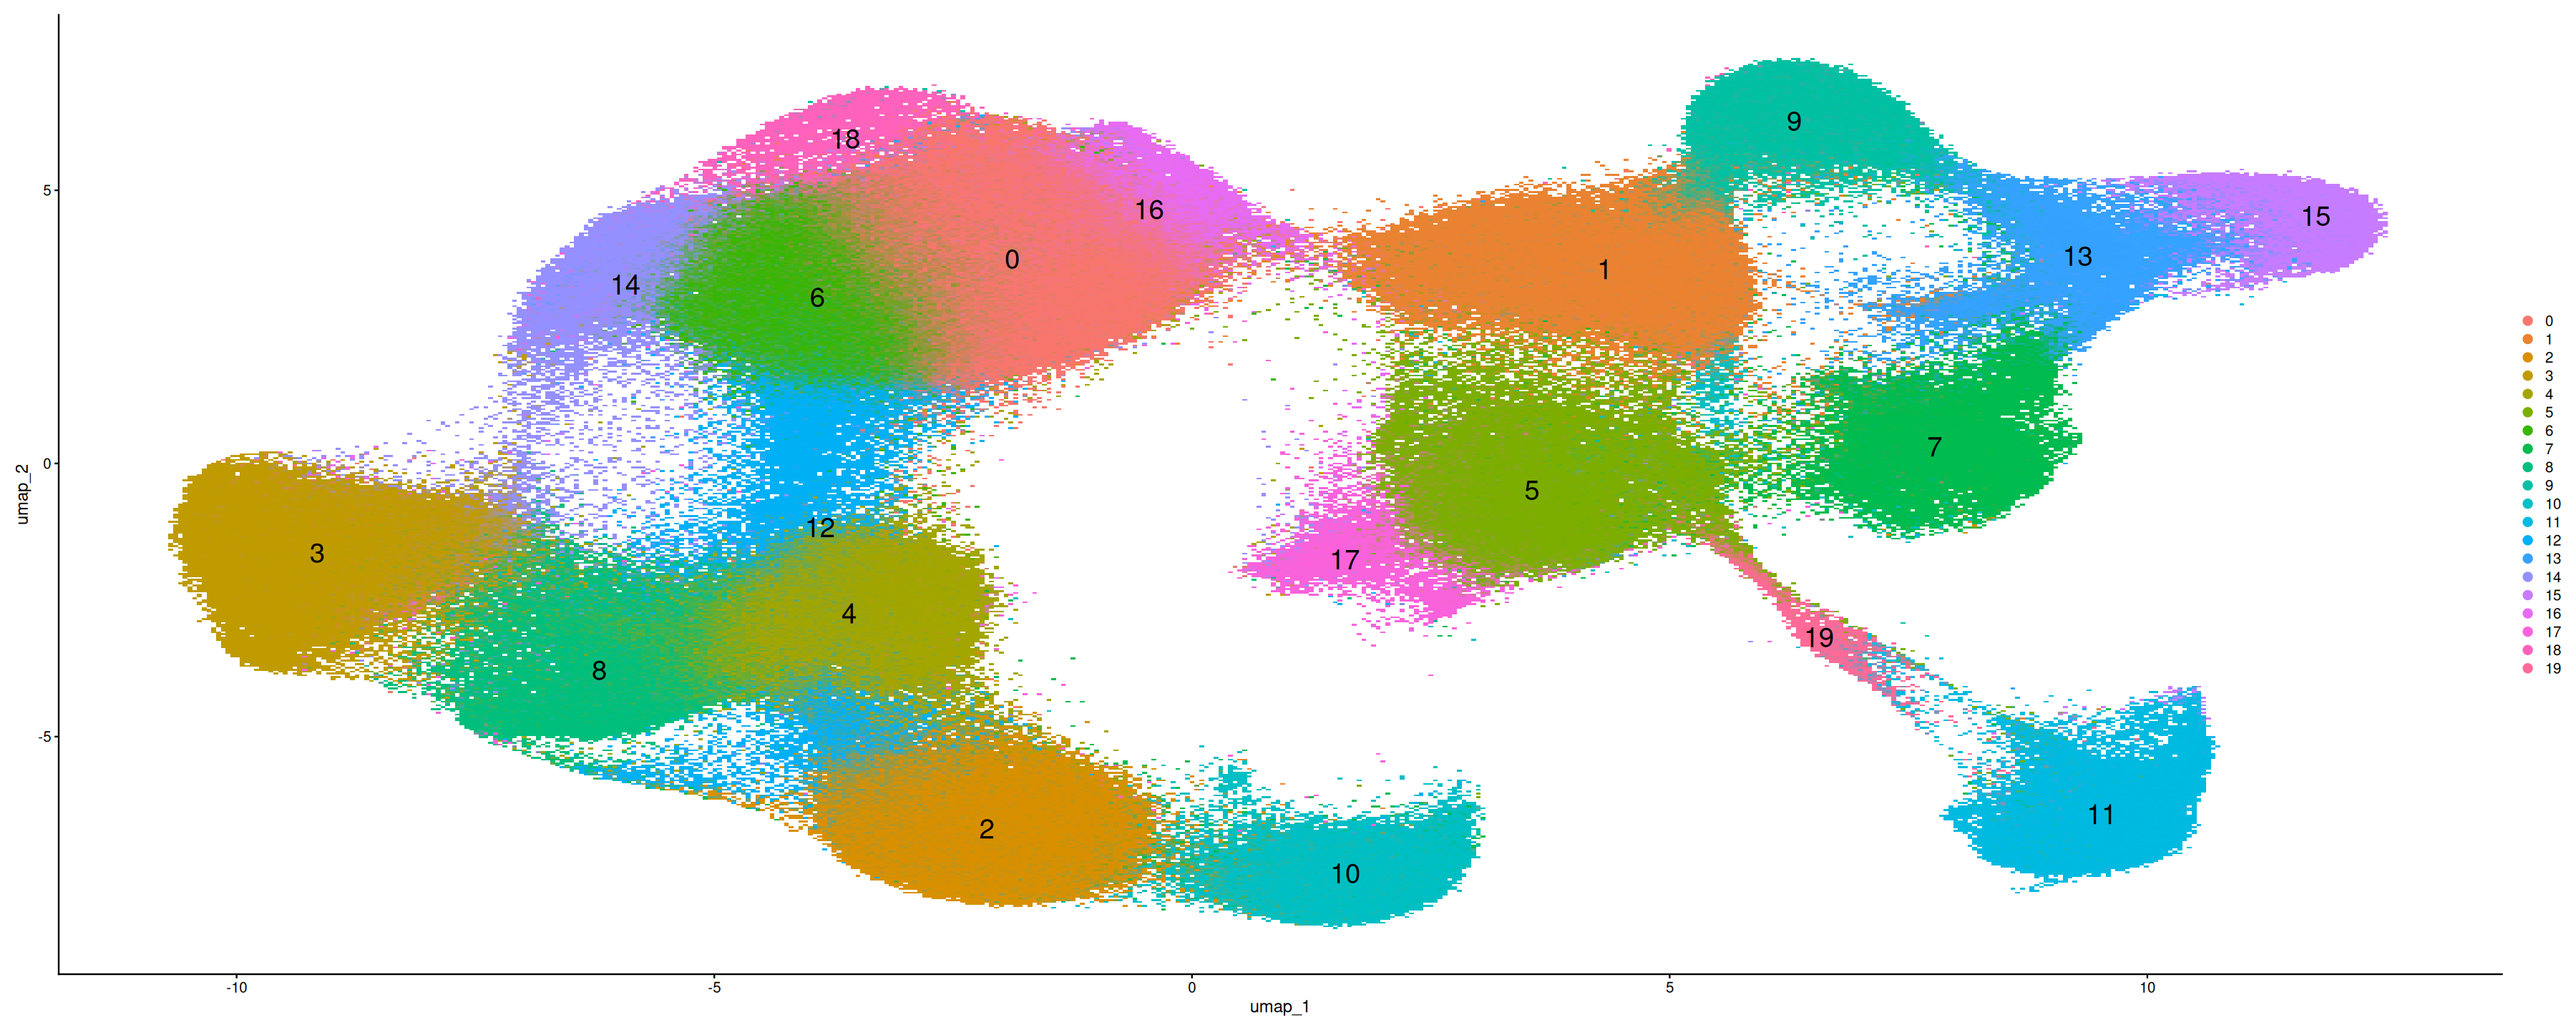

In [17]:
DimPlot(gut_allt_integrated, label = T, label.size = 8)

In [253]:
gut_allt_integrated  <- FindClusters(gut_allt_integrated, res = 0.25)

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 588063
Number of edges: 13479680

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9461
Number of communities: 11
Elapsed time: 918 seconds


In [ ]:
DimPlot(gut_allt_integrated, label = T, label.size = 8, group.by = "integrated_snn_res.0.3")

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



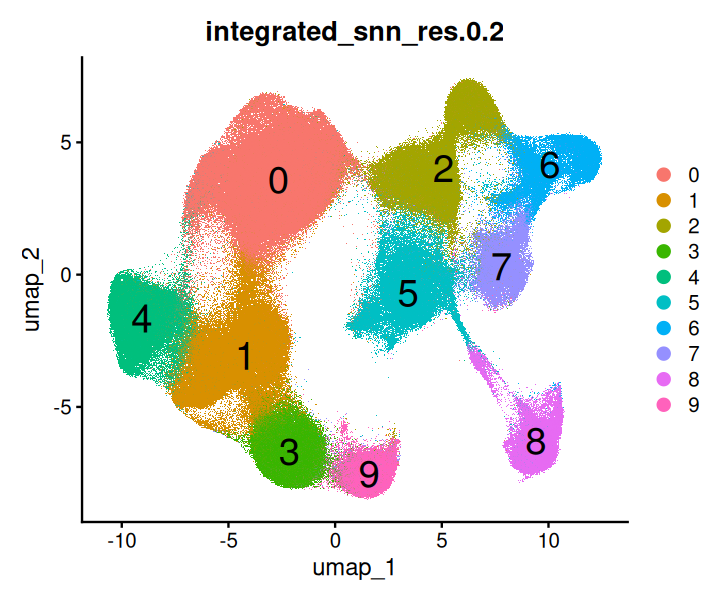

In [252]:
DimPlot(gut_allt_integrated, label = T, label.size = 8, group.by = "integrated_snn_res.0.2")

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



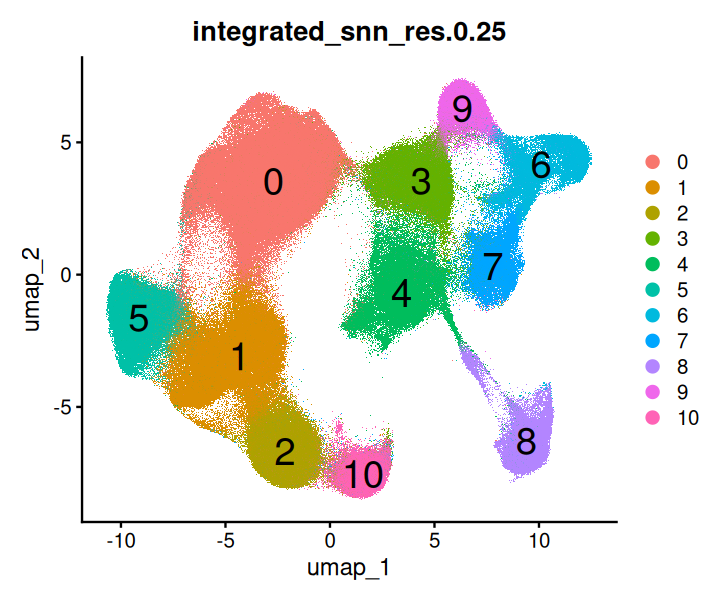

In [254]:
DimPlot(gut_allt_integrated, label = T, label.size = 8, group.by = "integrated_snn_res.0.25")

## Annotating clusters

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



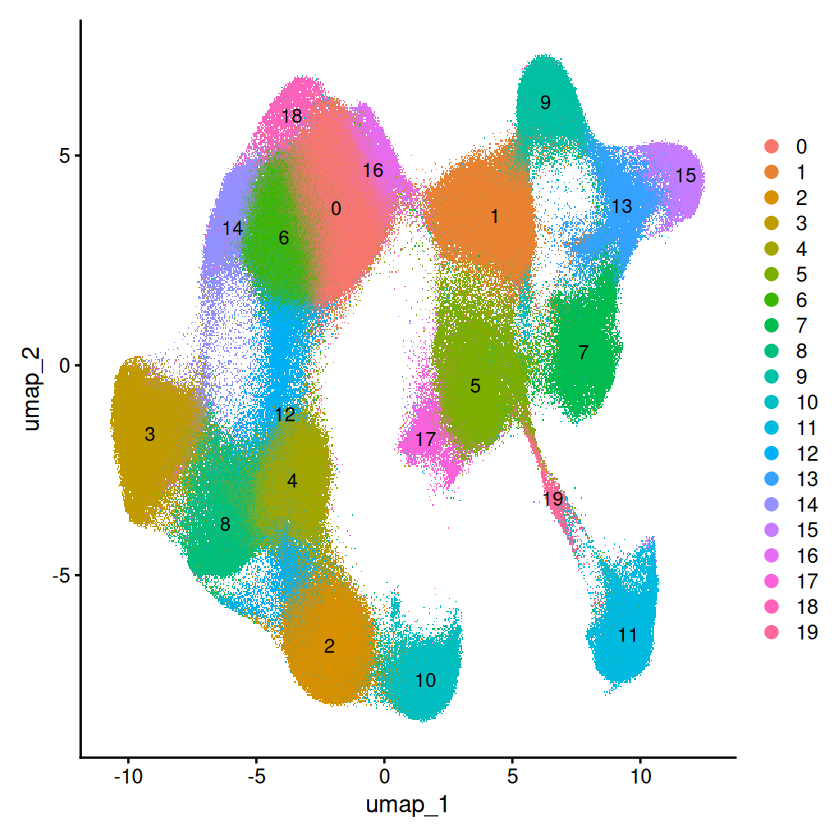

In [4]:
DimPlot(gut_allt_integrated, label = T)

In [ ]:
markers2  <- c("SELL", "CCR7", "LEF1", "TCF7", 
              "CXCR5", "GPR183", 
              "FOXP3", "IKZF2","IL2RA","TNFRSF18","CTLA4",
              "GATA3", "IL13","NEFL","PLP2","IL4", "ZBTB16",'IL5',
              "CCR6", "RORC" ,"IL17A","EOMES","IL17F","CXCR6","IL26",
              "ITGB1","S100A4","S100A6",
                   "IL23R","KLRB1","CCL5", "TBX21", "IFNG",
               "MKI67", "PCNA", "MCM6",
              "FASLG", "CST7","CCL5",'CXCR3',"CCL4",'XCL1','CD177','BATF',
               'IL22','RORA','CXCL13','IL21','GZMB',"GNLY","IL26",'PRF1',
'KLRD1','XCL1','CCL3L1','HLA-DRB5','HLA-DRA','CCL25',"TNF","CD40LG")

In [225]:
markers2  <- c("SELL", "CCR7", "LEF1", "TCF7","IL26","KLRB1")

In [241]:
DefaultAssay(gut_allt_integrated)  <- "RNA"
avgexp = AggregateExpression(gut_allt_integrated, features = markers2, group.by = "seurat_clusters", slot = "data",
                          assay = "RNA")

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



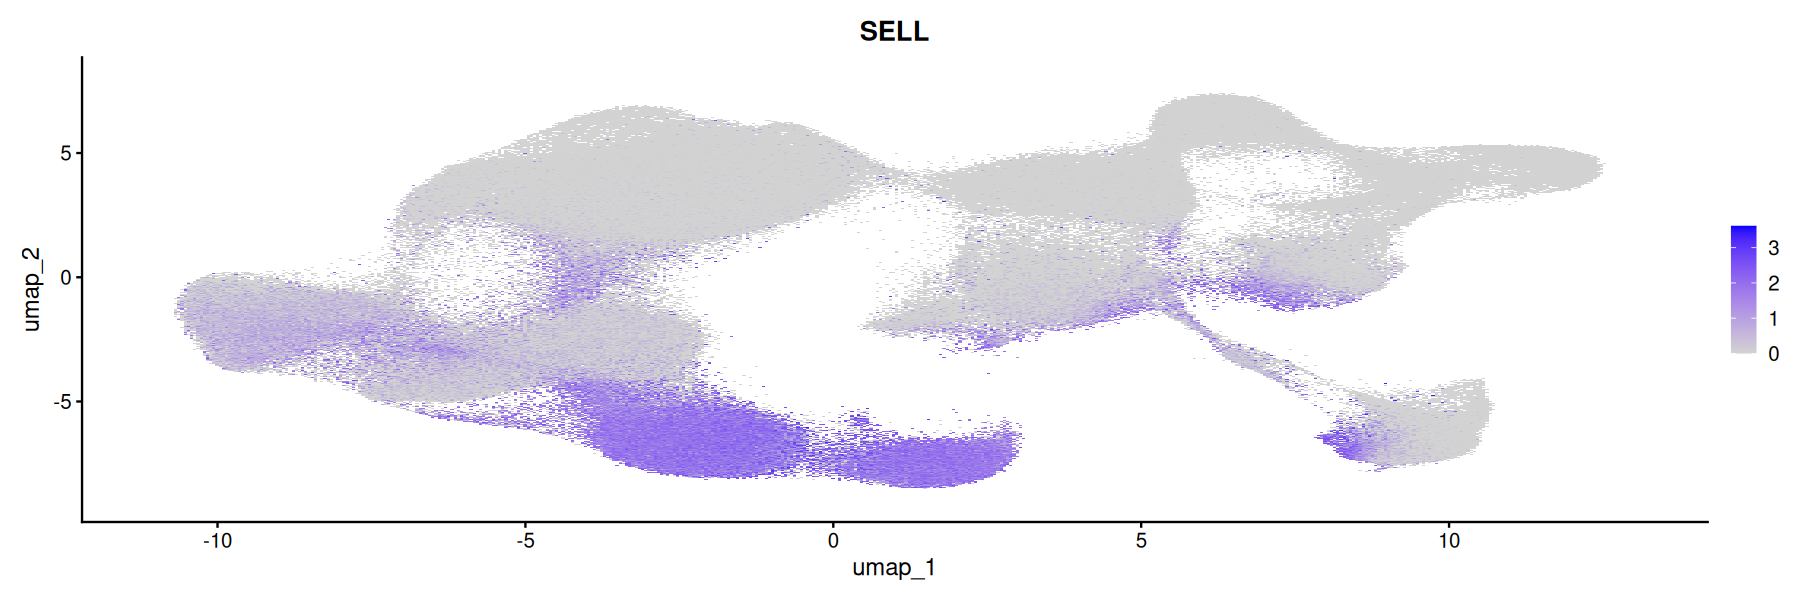

In [235]:
FeaturePlot(gut_allt_integrated, features = "SELL")

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



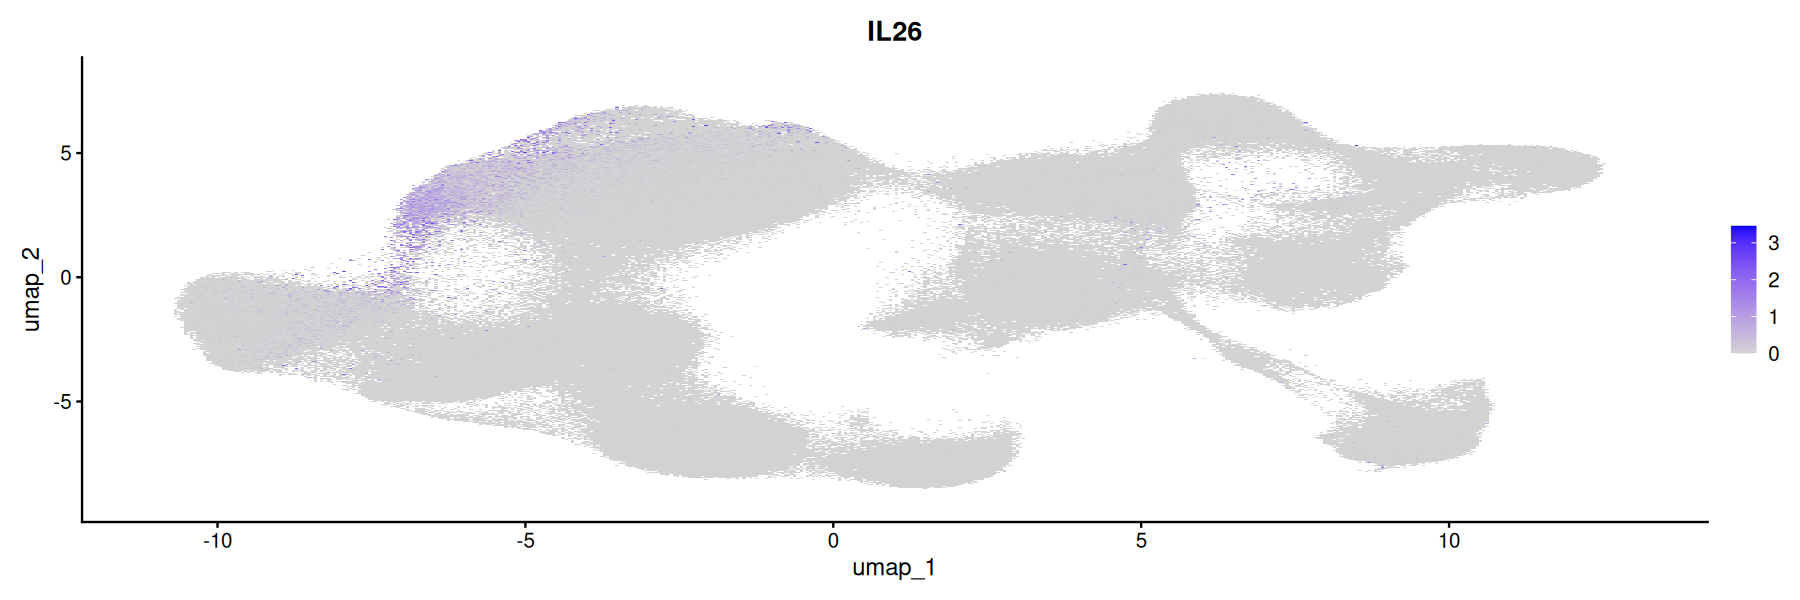

In [236]:
FeaturePlot(gut_allt_integrated, features = "IL26")

In [234]:
gut_allt_integrated

An object of class Seurat 
74202 features across 588063 samples within 3 assays 
Active assay: RNA (36601 features, 0 variable features)
 2 layers present: counts, data
 2 other assays present: integrated, RNA3
 2 dimensional reductions calculated: pca, umap

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



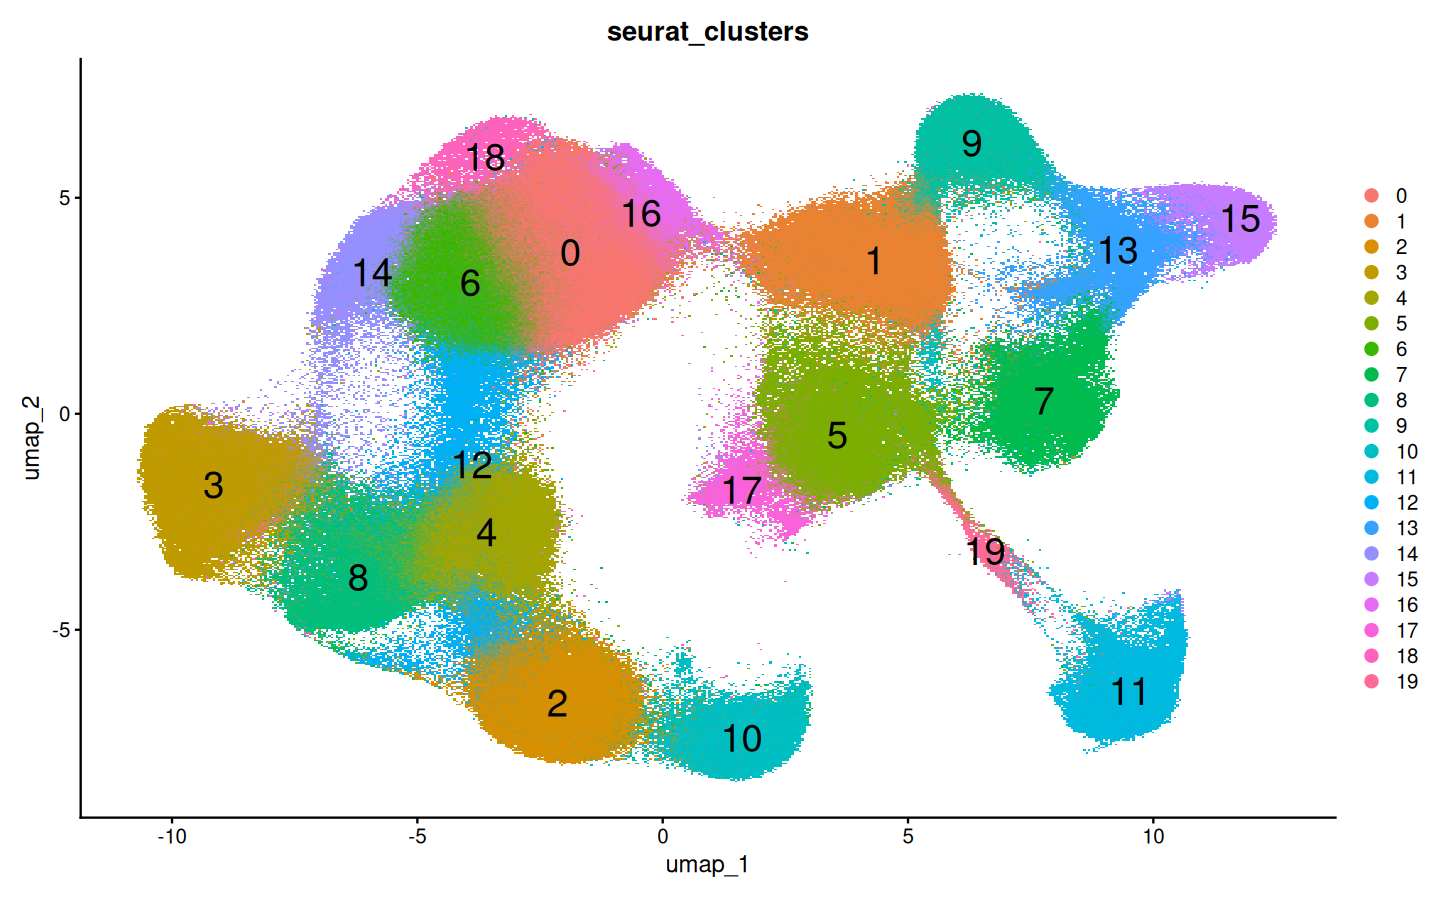

In [21]:
options(repr.plot.width = 12, repr.plot.height = 7.5)

DimPlot(gut_allt_integrated, group.by = "seurat_clusters", label = T, label.size = 8)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



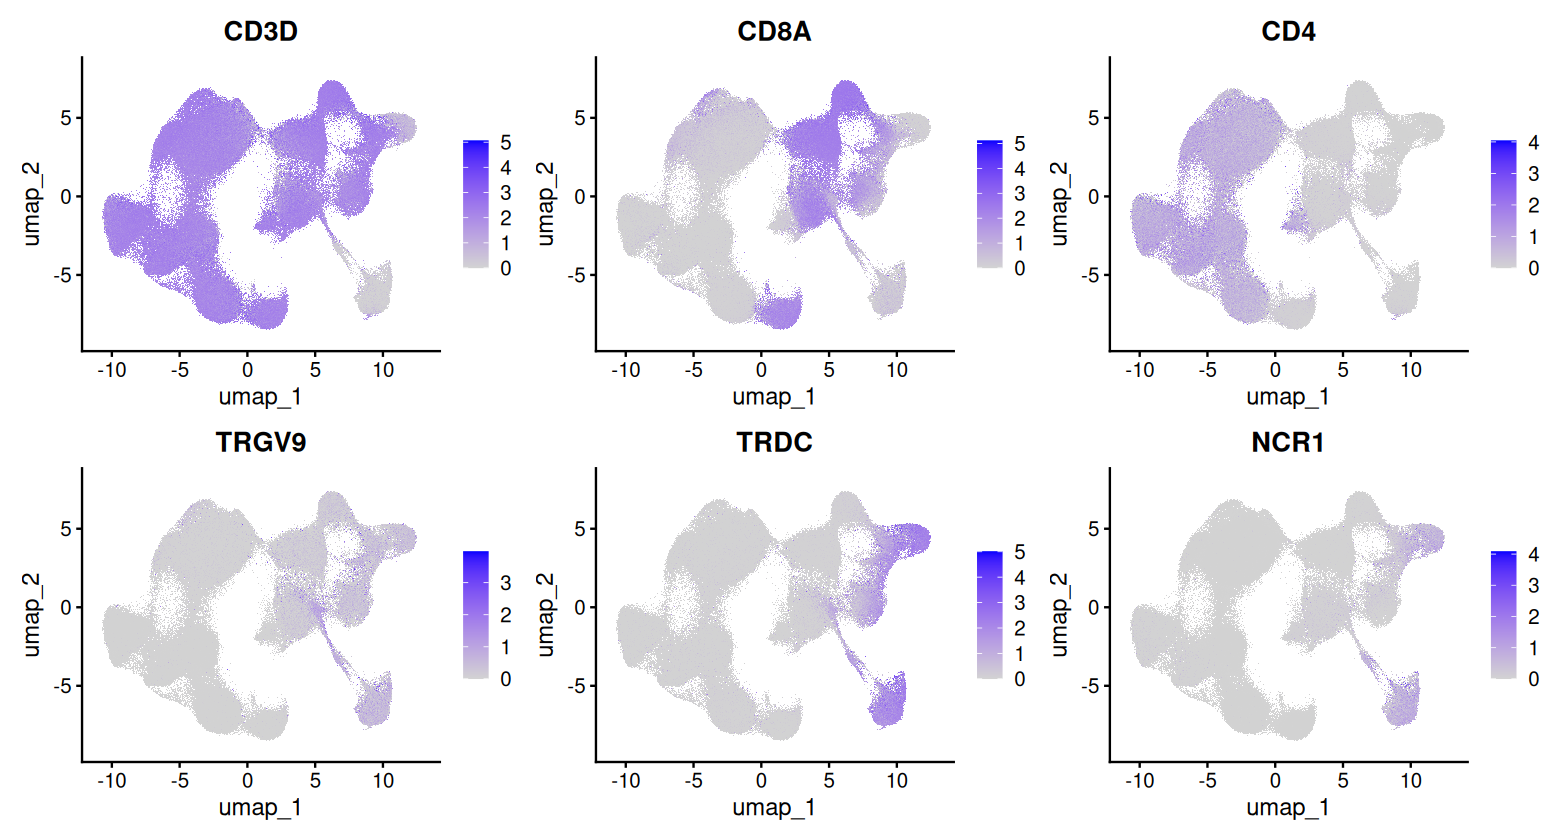

In [373]:
options(repr.plot.width = 13, repr.plot.height = 7)
FeaturePlot(gut_allt_integrated,features = c("CD3D","CD8A","CD4","TRGV9","TRDC","NCR1"), ncol = 3, min.cutoff = 0)

### Cluster tree

In [370]:
DefaultAssay(gut_allt_integrated)

[1] "integrated"

In [371]:
gut_allt_integrated <- BuildClusterTree(
  gut_allt_integrated,
  dims = 1:20,
  reorder = FALSE,
  reorder.numeric = FALSE
)

In [374]:
tree <- gut_allt_integrated@tools$BuildClusterTree
tree$tip.label <- paste0("Cluster ", tree$tip.label)

In [ ]:
colors  <- c(
    "#4c9c9cff", # Tem 
     "#92c0dfff", #Naive
     "#92c0dfff", #Naive
     "#2e8a3fff", # Temra
     "#92c0dfff", #Naive
     "#2e8a3fff", # Temra
    "#74bc68ff",  # Tcm
    "#74bc68ff",  # Tcm
    "#88aa00ff",
    "#4c9c9cff", # Tem 
    "#92c0dfff", #Naive
    "#4c9c9cff")

In [375]:
p <- ggtree::ggtree(tree, aes(x, y)) +
  scale_y_reverse() +
  ggtree::geom_tree() +
  ggtree::theme_tree() +
  ggtree::geom_tiplab(offset = 1) +
  ggtree::geom_tippoint(#color = colors, 
                        shape = 16, size = 5) +
  coord_cartesian(clip = 'off') +
  theme(plot.margin = unit(c(0,2.5,0,0), 'cm'))

#ggsave('plots/cluster_tree.png', p, height = 4, width = 6)

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


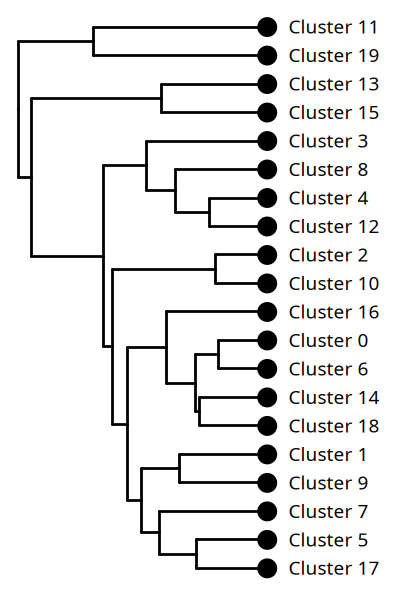

In [377]:
options(repr.plot.width=3.5, repr.plot.height=5)
p

### Marker heatmap

In [251]:
dim(gut_allt_integrated)

[1]  36601 588063

In [257]:
gut_allt_integrated

An object of class Seurat 
74202 features across 588063 samples within 3 assays 
Active assay: RNA (36601 features, 0 variable features)
 2 layers present: counts, data
 2 other assays present: integrated, RNA3
 2 dimensional reductions calculated: pca, umap

In [173]:
markers3  <- c('KLF2','SELL',"LEF1",'CCR7',"TCF7",
  #'GPR183','ITGB1',"NEFL",
  'BATF','TNFRSF18','IKZF2','CTLA4','IL2RA','FOXP3','ENTPD1',
  'IL21','CXCL13','CXCR5','IL4',
  'RORA','CCR6','S100A6','CST7', 'TBX21', 'S100A4', 'CCL3L1', 'KLRB1', 
  'ZBTB16', 'CCL25', 'TNF', 'FASLG', 'CD40LG', 'IL22', 'IL23R', 'IL17A', 
  'RORC', 'IL5', 'GATA3', 'XCL1', 'CCL5', 'CXCR3', 'CXCR6', 'PRF1', 
               'IL10',"IL19","MKI67","PCNA","MCM6",
               'IL13', 'IFNG', 'CCL4', 'HLA-DRB5', 'HLA-DRA', 'EOMES', 'GZMB', 'GNLY', 
  'KLRD1', 'IL17F', 'IL26'
 )

avgexp = AverageExpression(gut_allt_integrated, features = markers3, group.by = "seurat_clusters",
                           return.seurat = F,
                          assay = "RNA")

In [7]:
avgexp

  [[ suppressing 20 column names ‘g0’, ‘g1’, ‘g2’ ... ]]



$integrated
46 x 20 sparse Matrix of class "dgCMatrix"
                                                                    
KLF2      0.70506697  0.562394069 9.7356959865 0.76288502 1.11219647
SELL      0.10149843  0.065319304 6.4474289633 1.44150528 0.89395480
LEF1      0.30348033  0.194943621 6.0293908088 0.68585163 2.44407446
CCR7      0.24613345  0.252863391 7.5847324609 1.41742311 3.18362113
TCF7      1.15822569  1.645186319 5.5808022979 0.27718278 4.42221156
GPR183    6.58825869  3.666183656 3.9689658273 3.63789989 7.14656766
BATF      0.68235207  0.503205097 0.6095108564 6.11743309 1.66468188
TNFRSF18  0.58102238  0.067689451 0.0296141180 3.32052951 0.25299163
IKZF2     0.07503683  0.136880148 0.2119206510 1.40343192 0.30053789
CTLA4     0.47068001  0.068827815 0.4897181989 4.34605969 1.41458171
IL2RA     0.19489841  0.121065985 0.1000077078 1.89873759 0.20084850
FOXP3     0.12313082  0.055025837 0.1652860441 4.58678231 0.24736176
CD177     0.01116011  0.003750722 0.0023900682 0

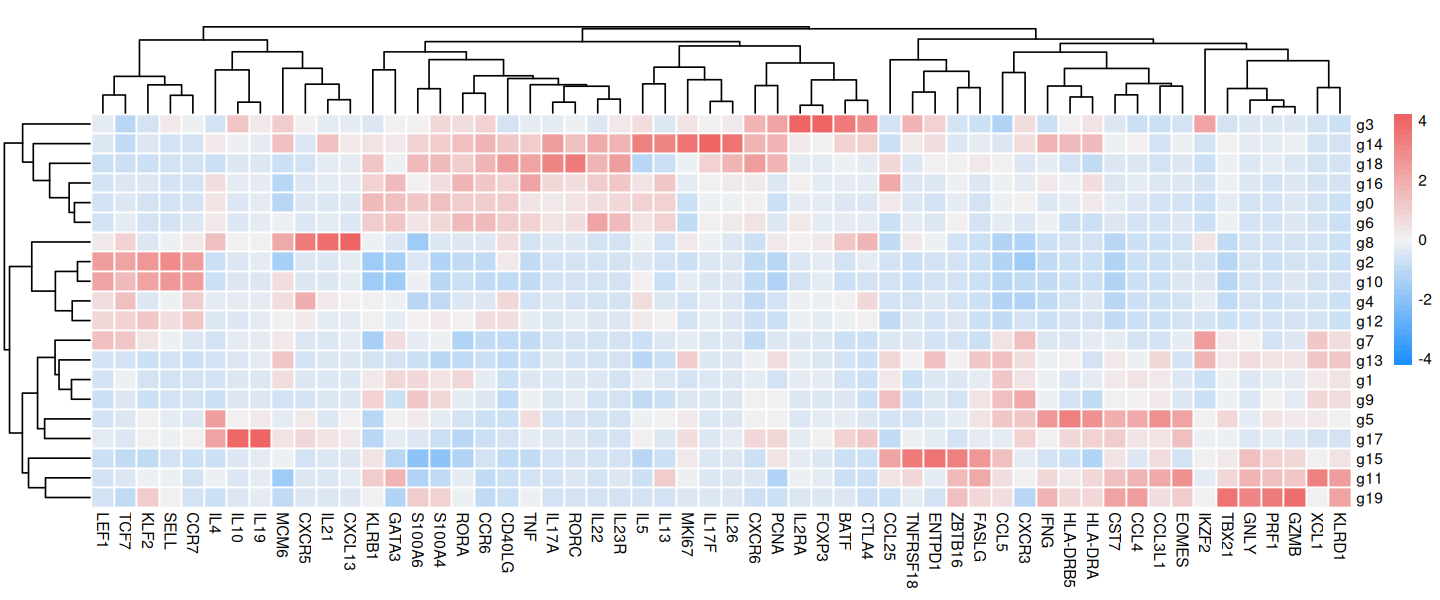

In [174]:
options(repr.plot.width = 12, repr.plot.height = 5)
pheatmap::pheatmap(t(avgexp$RNA), main = "", 
         scale = "column", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9)

In [169]:
markers1  <- rev(c("CD3D","CD4","CD8A","CD8B","TRDC","TRGC1","FCER1G","NCR1"))
avgexp = AverageExpression(gut_allt_integrated, features = markers1, group.by = "seurat_clusters",
                           return.seurat = F,
                          assay = "RNA")

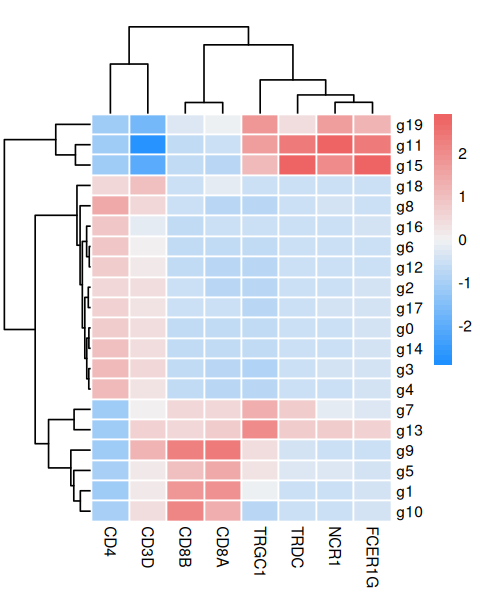

In [170]:
options(repr.plot.width = 4, repr.plot.height = 5)
pheatmap::pheatmap(t(avgexp$RNA), main = "", 
         scale = "column", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9)

In [105]:
mtx_ordered <- t(avgexp$RNA)[c(2,10,5,7,3,9,1,6,4,11,8),]

In [109]:
mtx_ordered2 <- as.matrix(mtx_ordered)[,match(markers3, colnames(mtx_ordered))]
mtx_ordered2

,KLF2,SELL,LEF1,CCR7,TCF7,GPR183,ITGB1,NEFL,BATF,TNFRSF18,⋯,IFNG,CCL4,HLA-DRB5,HLA-DRA,EOMES,GZMB,GNLY,KLRD1,IL17F,IL26
g1,9.3290113,7.61742833,6.4619170,7.0785000,6.8108969,4.013181,0.5909909,0.0120310507,0.6885399,0.01915915,⋯,0.01802438,0.0966652,0.2724409,0.7821456,0.02136629,0.007606033,0.02567232,0.01468868,0.001141434,0.0004225353
g9,6.7873263,2.96082144,3.1687248,4.5879569,4.4613203,5.547786,1.5052999,0.0739521103,1.2629697,0.42711706,⋯,0.12533250,0.1466722,0.3756998,0.8331242,0.01620357,0.009571564,0.05641459,0.03498248,0.017180225,0.0091396399
g4,0.9521329,0.88824202,2.8441184,3.8793189,5.1661908,7.444668,0.6074403,0.0107110052,1.5209878,0.18240488,⋯,0.07419529,0.1590220,0.3652586,0.9971850,0.01227010,0.008304094,0.02521046,0.01329410,0.010522115,0.0028159407
g6,3.4675777,2.86743269,3.4175120,4.1523759,2.8828204,3.952757,0.9371268,0.0024135569,3.3432258,2.05902939,⋯,0.12356974,0.2074729,0.4861199,1.0003465,0.02656951,0.030155296,0.03875721,0.03776899,0.064716051,0.0316605844
g2,0.8678189,1.66349104,0.8509288,1.4257759,0.2150668,3.794870,0.7909567,0.0007264467,6.2392759,4.10028266,⋯,0.10001890,0.3090068,0.7700555,1.4091353,0.01732631,0.116267389,0.22891943,0.02813588,0.063965406,0.1602815066
g8,0.5436351,0.80322257,1.4718430,1.5864984,5.5315037,3.530055,0.7501860,0.0009032855,2.9705867,1.17452746,⋯,0.08093650,0.1201805,0.3552449,0.8787730,0.01113457,0.003598741,0.01566441,0.01994733,0.006659416,0.0009602288
g0,1.3288481,0.17690022,0.4936754,0.5362619,1.9563530,6.000160,0.7586000,0.0184475896,0.8281746,0.71607613,⋯,0.76055823,1.3490163,0.4015396,1.0194500,0.04891774,0.070748001,0.17768505,0.03972759,0.004510929,0.0112352410
g5,1.0974748,0.11692470,0.3794923,0.3690927,1.7982927,5.448623,0.6781588,0.0091219644,0.8577073,0.50735115,⋯,0.84443378,1.9294442,0.5534729,1.4061084,0.04979350,0.060641877,0.15214551,0.07419839,0.008098591,0.0413472363
g3,0.5302948,0.04135651,0.1662201,0.2447020,1.2399440,4.415545,0.8007439,0.0049586693,1.1942208,0.67555448,⋯,0.20268719,0.7225714,0.4478638,1.1197625,0.02230743,0.076565229,0.09244853,0.07767620,0.106894103,0.2409890699
g10,0.6015342,0.08506835,0.2867635,0.2264664,1.2647778,2.242205,0.6977962,0.0097201697,1.2288467,0.49209435,⋯,0.30798718,1.0657302,0.4183342,0.9153405,0.04810724,0.090642126,0.16032760,0.17704021,0.097531289,0.2440902616


In [112]:
dir.create("figures/characterization_CD4CTL/")

In [113]:
pheatmap::pheatmap(mtx_ordered2, main = "", 
         scale = "column", cluster_cols = F, cluster_rows = F,
        color=colorRampPalette(c("dodgerblue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9, filename = "figures/characterization_CD4CTL/heatmap_cluster_markers_5p.pdf",
                  width = 12, height = 4)

### Annotating clusters

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



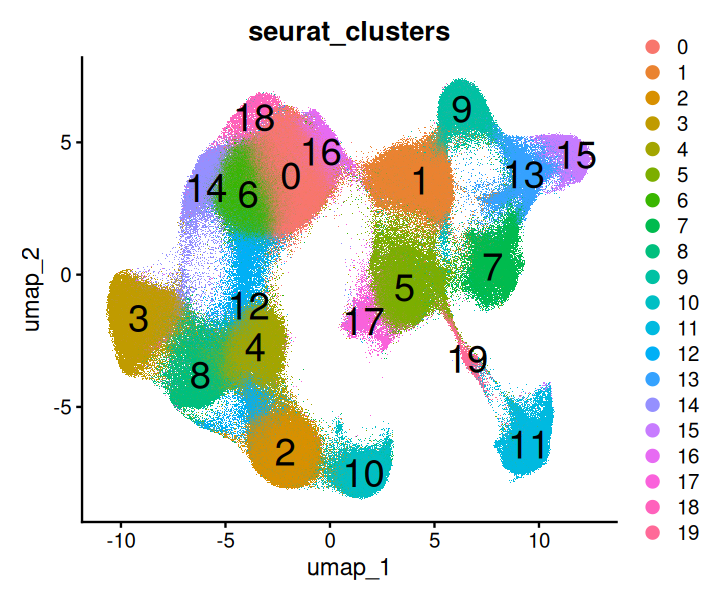

In [33]:
DimPlot(gut_allt_integrated, group.by = "seurat_clusters", label = T, label.size = 8)

In [ ]:
gut_allt_integrated@meta.data <- gut_allt_integrated@meta.data  %>% mutate(annotations = recode_factor(seurat_clusters, 
"0" = "CD4 Th17_1",                                                                         
"1" = "CD8 memory",
"2" = "CD4 Naive",
"3" = "CD4 Treg",
"4" = "CD4 Tcm",
"5" = "CD8 Memory",
"6" = "CD4 Th17_2",
"7" = "CD8 Tgd",
"8" = "CD4 Tfh",
"9" = "IEL CD8",
"10" = "CD8 Naive",
"11" = "NK cells",
"12" = "CD4 Tcm",
"13" = "IEL Tgd",
"14" = "CD4 CTL",
"15" = "IEL NK cells",
"16" = "CD4 Th17_3",
"17" = "CD4 Tr1-like",
"18" = "IEL CD4",
"19" = "NK cells"))

## Coarse annotations

In [22]:
gut_allt_integrated  <- FindClusters(gut_allt_integrated, res = c(0.2))

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 588063
Number of edges: 13479680

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9525
Number of communities: 10
Elapsed time: 728 seconds


Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



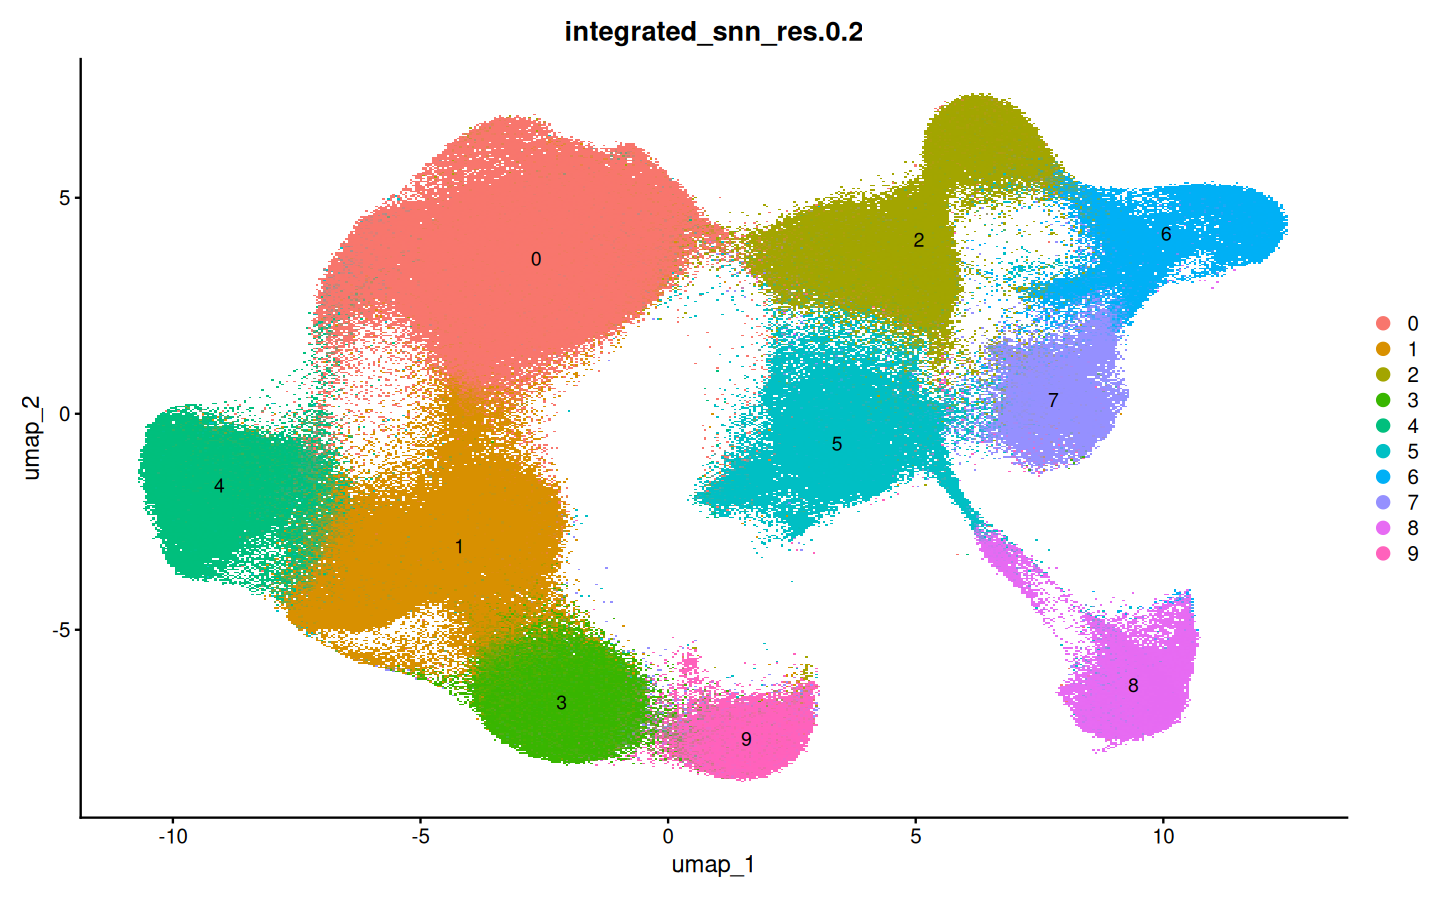

In [23]:
DimPlot(gut_allt_integrated, group.by = "integrated_snn_res.0.2", label = T)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



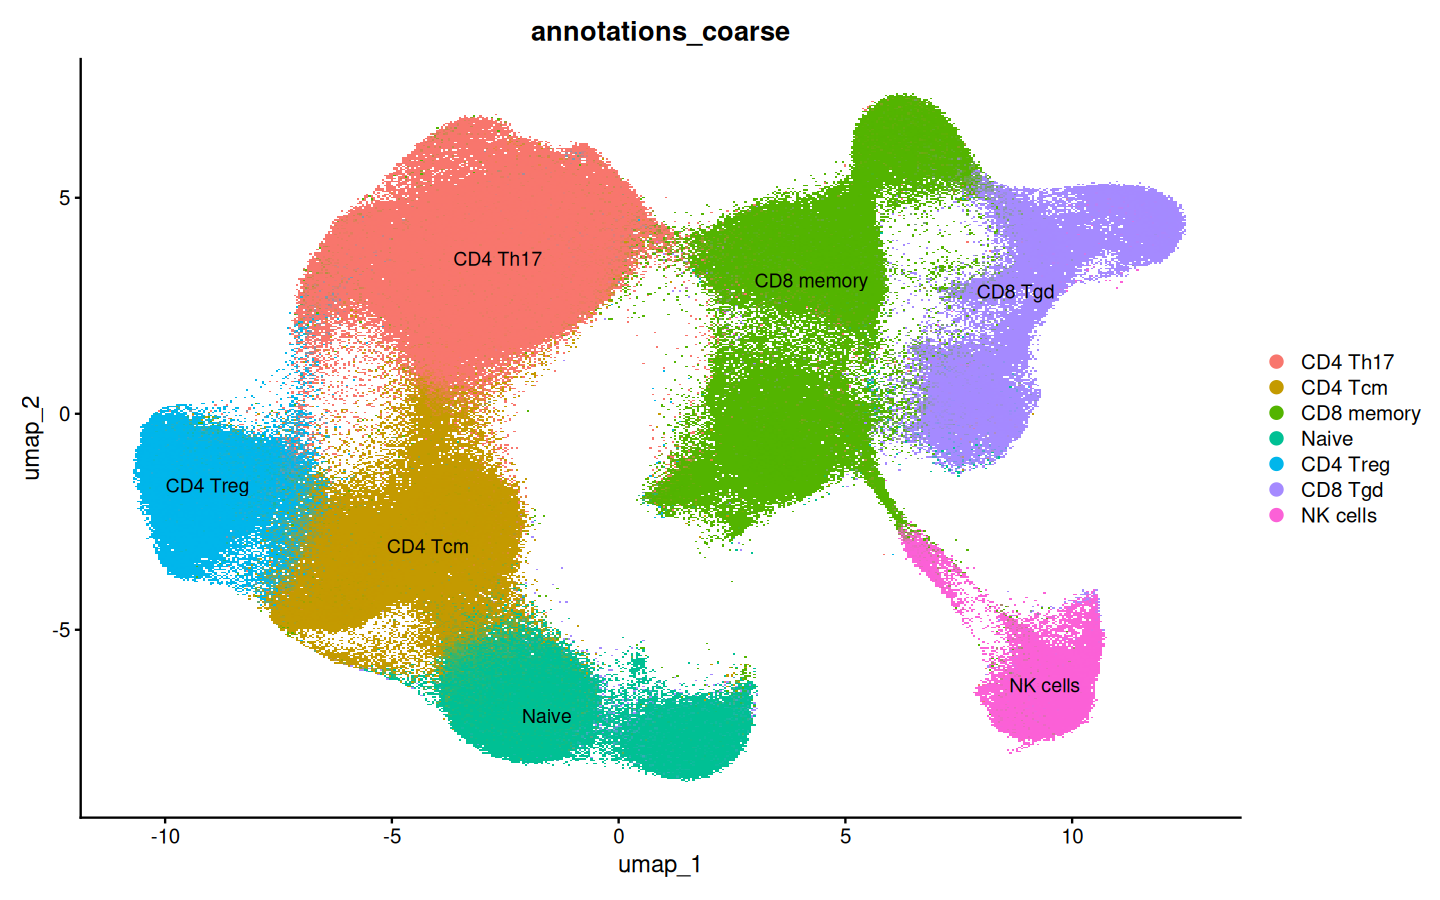

In [24]:
gut_allt_integrated@meta.data <- gut_allt_integrated@meta.data  %>% mutate(annotations_coarse = recode_factor(integrated_snn_res.0.2, 
"0" = "CD4 Th17",                                                                         
"1" = "CD4 Tcm",
"2" = "CD8 memory",
"3" = "Naive",
"4" = "CD4 Treg",
"5" = "CD8 memory",
"6" = "CD8 Tgd",
"7" = "CD8 Tgd",
"8" = "NK cells",
"9" = "Naive"))

DimPlot(gut_allt_integrated, group.by = "annotations_coarse", label = T)

Use nice colors for visualization

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



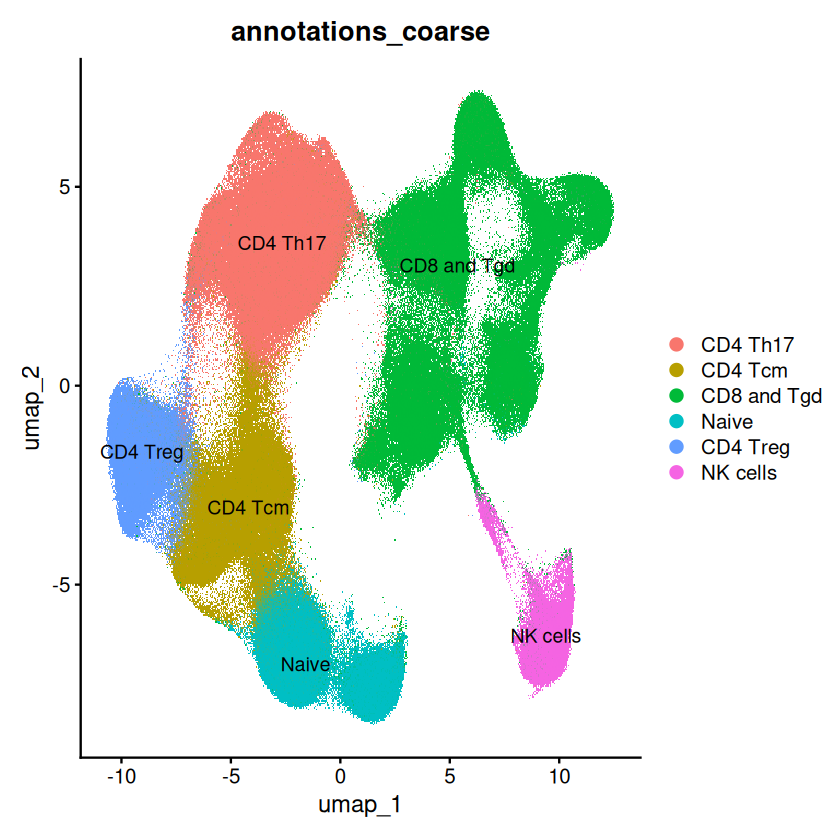

In [6]:
gut_allt_5p@meta.data <- gut_allt_5p@meta.data  %>% mutate(annotations_coarse = recode_factor(integrated_snn_res.0.2, 
"0" = "CD4 Th17",                                                                         
"1" = "CD4 Tcm",
"2" = "CD8 and Tgd",
"3" = "Naive",
"4" = "CD4 Treg",
"5" = "CD8 and Tgd",
"6" = "CD8 and Tgd",
"7" = "CD8 and Tgd",
"8" = "NK cells",
"9" = "Naive"))

DimPlot(gut_allt_5p, group.by = "annotations_coarse", label = T)

In [7]:
pallete  <- c("Naive" = "#b288d9ff",
              "CD4 Tcm" = "#d9a988ff",
              "CD4 Th17" = "#b1d988ff",
              "CD4 Treg" = "#f0c963ff",
              "CD8 and Tgd" = "#88d9c4ff",
              "IEL" = "#88b8d9ff",
              "NK cells" = "#88b8d8ff")

In [ ]:
#options(repr.plot.width = 16, repr.plot.height = 14)
options(repr.plot.width = 5, repr.plot.height = 4)
DimPlot(gut_allt_5p, group.by = "annotations_coarse", cols = pallete)